# From Combine Cuts to Game Performance: Kinematic Cut Efficiency (KCE)

NFL Big Data Bowl 2027, Track 01. This notebook runs the **real-data** pipeline
end-to-end (no synthetic rows):

1. Load the derived tables built from the official CSVs (`src/build_tables.py`);
   if the cache is missing they are rebuilt from the raw tracking files.
2. Demonstrate the acceleration fix: the shipped `a` column is an **unsigned
   magnitude** (`min = 0.000`, `0.0000%` negative over 463,189 rows), so every
   kinematic quantity here is differentiated from `(x, y)` with a
   **Savitzky-Golay** filter (window 11 frames, 3rd order, 10 Hz).
3. Detect cuts (>35 deg direction change), label break direction from the 2-D
   velocity cross product, and keep the drill-name **alignment side** as a
   separate feature (alignment side is *not* the break direction).
4. Build the target inventory: official `separation_at_pass_forward`, athlete
   mean separation, separation gain, career snaps, and the *attempted*
   tracking-derived proxy (validated honestly, then rejected).
5. Fit the models: LightGBM + HistGradientBoosting under GroupKFold by athlete
   and by game-play, bracketed by a mean baseline and a shuffled-label null,
   plus statsmodels MixedLM with random intercepts.


In [2]:
import os, sys, json, time
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# the kernel (and src/run_notebook.py) start inside notebooks/; every cell
# below is written against the PROJECT ROOT, so move there exactly once
if os.path.basename(os.path.abspath(".")) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
import kce_features, kce_model, run_analysis
print("pandas", pd.__version__, "| numpy", np.__version__)
print("lightgbm available:", kce_model.HAVE_LIGHTGBM)
from sklearn.ensemble import HistGradientBoostingRegressor
print("sklearn HistGradientBoosting: yes | statsmodels:",
      __import__("statsmodels").__version__)
os.makedirs(os.path.join("outputs", "figures"), exist_ok=True)
DATA = os.path.join("data", "kaggle_nfl", "nfl_data")
print("tracking files:", sorted(os.listdir(DATA)))
print("cwd:", os.getcwd())


pandas 2.3.3 | numpy 2.2.6
lightgbm available: True
sklearn HistGradientBoosting: yes | statsmodels: 0.14.6
tracking files: ['combine_results.csv', 'combine_tracking.csv', 'game_tracking_2023.csv', 'games.csv', 'player_career_successes.csv', 'player_play.csv', 'players.csv']
cwd: /home/pope/Desktop/gpu /hackathons/01-nfl-big-data-bowl-2027


In [3]:
# 1) derived tables (built from the real CSVs); rebuild only if the cache is absent
if not os.path.exists(os.path.join("outputs", "cache", "play_features.csv")):
    sys.path.insert(0, "src")
    from build_tables import main as build
    build()
from run_analysis import load_tables, build_frames, headline_scores, PLAY_KIN, PRE_SNAP_CTX
t = load_tables()
comb, pf, players, pp, pcs = build_frames(t)
print({k: len(v) for k, v in t.items()})
print("combine athletes:", comb.nfl_id.nunique(),
      "| cut events:", len(t["cuts"]),
      "| play-level rows:", len(pf))


{'sess': 6310, 'cuts': 5618, 'comb': 510, 'pf': 30959, 'dv': 7268, 'cr': 510, 'players': 510, 'pcs': 510, 'pp': 314197}
combine athletes: 510 | cut events: 5618 | play-level rows: 30959


shipped a: min=0.000 max=10.718 negative fraction=0.0000% -> UNSIGNED
 cut_frame  turn_deg break_side   kce   dbr
        16   176.311  UNALIGNED 0.189 1.131
        57    96.247  UNALIGNED 0.473 1.250


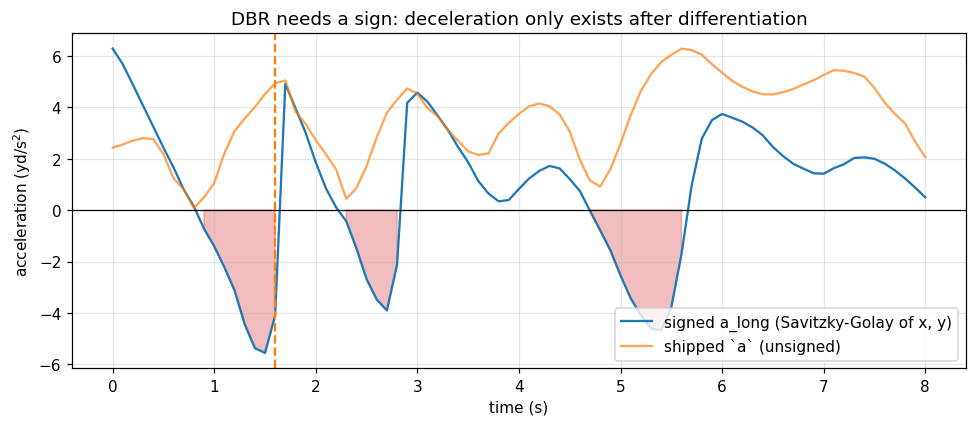

In [4]:
# 2) the acceleration fix: unsigned shipped column vs Savitzky-Golay signed derivative
from kce_features import savgol_kinematics, detect_cuts
ct = t.get("_ct")
if ct is None:
    ct = pd.read_csv(os.path.join(DATA, "combine_tracking.csv"),
                     usecols=["event_id", "nfl_id", "entity_type", "time",
                              "drill_name", "attempt", "x", "y", "a"],
                     parse_dates=["time"])
ct = ct[ct.entity_type == "PLAYER"].sort_values(["event_id", "nfl_id", "time"])
print(f"shipped a: min={ct.a.min():.3f} max={ct.a.max():.3f} "
      f"negative fraction={(ct.a < 0).mean():.4%} -> UNSIGNED")

pick = None
for k, g in ct.groupby(["event_id", "nfl_id", "drill_name", "attempt"]):
    if "THREE_CONE" not in g.drill_name.iloc[0] or len(g) < 40:
        continue
    x, y = g.x.to_numpy(float), g.y.to_numpy(float)
    kin = savgol_kinematics(x, y); kin["x"], kin["y"] = x, y
    c = detect_cuts(kin, g.drill_name.iloc[0])
    if len(c) and c.decel_peak.max() > 3:
        pick = (g, kin, c); break
g, kin, c = pick
tt = np.arange(len(g)) * 0.1
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tt, kin["a_long"], label="signed a_long (Savitzky-Golay of x, y)")
ax.plot(tt, g.a.to_numpy(float), alpha=.7, label="shipped `a` (unsigned)")
ax.axhline(0, color="k", lw=.8); ax.axvline(c.iloc[0].cut_frame * .1, ls="--", color="tab:orange")
ax.fill_between(tt, kin["a_long"], 0, where=kin["a_long"] < 0, alpha=.3, color="tab:red")
ax.set(xlabel="time (s)", ylabel="acceleration (yd/s$^2$)",
       title="DBR needs a sign: deceleration only exists after differentiation")
ax.legend(); ax.grid(alpha=.3); fig.tight_layout()
print(c[["cut_frame", "turn_deg", "break_side", "kce", "dbr"]].round(3).to_string(index=False))


In [5]:
# 3) cuts across the whole combine: KCE / DBR / alignment vs break direction
cuts = t["cuts"]
print("cut events:", len(cuts), "| athletes:", cuts.nfl_id.nunique())
print("break side:", cuts.break_side.value_counts().to_dict())
print("alignment side (from drill NAME):", cuts.align_side.value_counts().to_dict())
print(cuts[["kce", "dbr", "cut_angle_deg", "speed_retention"]]
      .describe().round(3).to_string())
side = cuts[cuts.align_side != "NONE"]
per = side.groupby("drill").agg(n=("turn", "size"),
                                frac_left_turn=("turn", lambda s: (s == "LEFT").mean()),
                                side=("align_side", "first"))
print("\nLEFT-suffixed drills are NOT all left-breaking (alignment != break):")
print(per.sort_values("frac_left_turn").round(3).to_string())


cut events: 5618 | athletes: 509
break side: {'UNALIGNED': 4822, 'INSIDE': 470, 'OUTSIDE': 326}
alignment side (from drill NAME): {'NONE': 4822, 'RIGHT': 626, 'LEFT': 170}
            kce       dbr  cut_angle_deg  speed_retention
count  5618.000  5618.000       5618.000         5618.000
mean      0.604     0.913         87.297            1.082
std       0.287     0.647         45.975            0.274
min       0.000     0.000         35.007            0.398
25%       0.329     0.527         47.440            0.920
50%       0.714     0.903         71.134            1.047
75%       0.854     1.091        128.242            1.180
max       0.964     6.475        180.000            3.224

LEFT-suffixed drills are NOT all left-breaking (alignment != break):
                                      n  frac_left_turn   side
drill                                                         
END_ZONE_FADE_RIGHT                   1           0.000  RIGHT
IN_ROUTE_LEFT                        29        

In [6]:
# 4) target inventory + honest proxy validation
targets = {
    "sep_at_pass_forward (official, play level)": int(pf.separation_at_pass_forward.notna().sum()),
    "sep_gain = sep - cushion (official, play level)": int(pf.sep_gain.notna().sum()),
    "derived_sep_pf (tracking-derived proxy)": int(pf.derived_sep_pf.notna().sum()),
}
pl = run_analysis.player_level_frame(pp, comb, pcs)
targets["player_mean_sep (official, athlete level)"] = int(pl.player_mean_sep.notna().sum())
targets["player_mean_yac (official, athlete level)"] = int(pl.player_mean_yac.notna().sum())
career = comb.merge(pcs, on="nfl_id", how="left")
targets["career_snaps_log (official, athlete level)"] = len(career)
for k, v in targets.items():
    print(f"{k:52s} rows={v:,}")

v = pf[pf.derived_sep_pf.notna() & pf.separation_at_pass_forward.notna()]
r = v.derived_sep_pf.corr(v.separation_at_pass_forward)
print(f"\nproxy validation: Pearson r={r:.3f} over {len(v):,} rows -> "
      f"{'ACCEPTED' if abs(r) >= 0.4 else 'REJECTED (sparse tracking: 1.6 athletes/play)'}")


sep_at_pass_forward (official, play level)           rows=9,359
sep_gain = sep - cushion (official, play level)      rows=8,715
derived_sep_pf (tracking-derived proxy)              rows=4,105
player_mean_sep (official, athlete level)            rows=145
player_mean_yac (official, athlete level)            rows=122
career_snaps_log (official, athlete level)           rows=510

proxy validation: Pearson r=0.033 over 4,078 rows -> REJECTED (sparse tracking: 1.6 athletes/play)


In [7]:
# 5) models: GroupKFold by athlete AND by game-play, baselines + shuffled null
kin = [c for c in PLAY_KIN if c in pf.columns]
ctx = [c for c in PRE_SNAP_CTX if c in pf.columns]
cmb = [c for c in comb.columns if comb[c].dtype.kind in "if"
       and c not in ("nfl_id", "draft_year")]           # athlete-level combine feats
full = kin + [f"cmb_{c}" for c in cmb if f"cmb_{c}" in pf.columns] + ctx
print("features:", len(full))

t0 = time.time()
res = kce_model.evaluate_target(pf, "separation_at_pass_forward", full,
                                {"by_player": pf.nfl_id.to_numpy(),
                                 "by_game_play": pf.game_play_id.to_numpy()})
print(f"evaluated in {time.time() - t0:.1f}s; rows={res['rows']:,}")
summary = headline_scores(res)
print(pd.DataFrame(summary).T.round(4).to_string())


features: 102
evaluated in 40.3s; rows=9,359
                                                                                            lightgbm                                                                                hist_gb                                                                                   mean_dummy                                                                        shuffled_label_null
by_player      {'r2': 0.2612733677276017, 'mae': 1.409154296451021, 'spearman': 0.46775747722582184}  {'r2': 0.2632777848176341, 'mae': 1.4088518668567012, 'spearman': 0.4677670745406627}  {'r2': -0.0005926588190574567, 'mae': 1.7063929762337207, 'spearman': -0.02172450213793579}   {'r2': -0.0570200769972129, 'mae': 1.754818683768137, 'spearman': 0.0021187727782181883}
by_game_play  {'r2': 0.28202882579690325, 'mae': 1.3863651847027763, 'spearman': 0.4900692059007518}  {'r2': 0.27858522825281806, 'mae': 1.3935826478313733, 'spearman': 0.484516964911598}  {'r2': -0.000175871139

In [8]:
# 6) mixed effects: player / game random intercepts + the directional KCE model
sub = pf.dropna(subset=["speed_at_pf", "release_time_s", "path_efficiency",
                        "max_speed", "cushion", "snap_to_pf_s"])
fml = ("separation_at_pass_forward ~ speed_at_pf + release_time_s + "
       "path_efficiency + max_speed + cushion + snap_to_pf_s + C(route_ran)")
m_player = kce_model.run_mixedlm(sub, fml, "nfl_id", label="player RI")
m_game = kce_model.run_mixedlm(sub, fml, "game_id", label="game RI")
m_team = kce_model.run_mixedlm(sub, fml, "nfl_id", vc={"team": "0 + C(team_abbr)"},
                               label="player RI + team VC")
for nm, m in [("player RI", m_player), ("game RI", m_game), ("player+team", m_team)]:
    print(f"{nm:14s} converged={m.get('converged')} rows={m.get('rows')} "
          f"in-sample R2={m.get('r2_fitted_insample', float('nan')):.4f}")
print({k: round(v, 5) for k, v in m_player.get("params", {}).items()})

# drill_base is deliberately NOT in this formula: alignment side is encoded in
# the drill NAME, so including both makes the alignment coefficient
# non-identifiable (p = nan, coefficient swings ~40 KCE units across optimisers)
kce_dir = kce_model.run_mixedlm(t["cuts"],
                                "kce ~ cut_angle_deg + approach_speed + "
                                "speed_retention + C(align_side)",
                                "nfl_id", label="directional KCE")
print("\ndirectional KCE model converged:", kce_dir.get("converged"))
print({k: (round(v, 5), f"p={kce_dir['pvalues'][k]:.4g}")
       for k, v in kce_dir.get("params", {}).items()})


player RI      converged=True rows=8697 in-sample R2=0.2039
game RI        converged=True rows=8697 in-sample R2=0.2169
player+team    converged=True rows=8697 in-sample R2=0.2037
{'Intercept': 1.63075, 'C(route_ran)[T.CROSS]': 0.37892, 'C(route_ran)[T.FLAT]': 1.60622, 'C(route_ran)[T.GO]': -0.36284, 'C(route_ran)[T.HITCH]': -0.04261, 'C(route_ran)[T.IN]': -0.12377, 'C(route_ran)[T.OUT]': -0.13875, 'C(route_ran)[T.POST]': -0.0974, 'C(route_ran)[T.SCREEN]': 3.08851, 'C(route_ran)[T.SLANT]': 0.03377, 'speed_at_pf': -0.08525, 'release_time_s': 0.11513, 'path_efficiency': -0.00086, 'max_speed': 0.11275, 'cushion': 0.19277, 'snap_to_pf_s': -0.04945, 'Group Var': 0.01111}

directional KCE model converged: False
{'Intercept': (1.13416, 'p=0'), 'C(align_side)[T.NONE]': (-0.00301, 'p=0.2327'), 'C(align_side)[T.RIGHT]': (0.00801, 'p=0.003698'), 'cut_angle_deg': (-0.00618, 'p=0'), 'approach_speed': (-0.00112, 'p=0.1464'), 'speed_retention': (0.01255, 'p=4.431e-12'), 'Group Var': (0.02342, 'p=0.00

In [9]:
# 7) figures (rendered inline) + headline vs the previous run
# NOTE: IPython/traitlets is not importable in this environment, so the
# summary is printed instead of displayed.
figs = sorted(f for f in os.listdir(os.path.join("outputs", "figures"))
              if f.endswith(".png"))
for f in figs:
    print(f)
with open(os.path.join("outputs", "model_metrics.json")) as fh:
    metrics = json.load(fh)
print(json.dumps(metrics["headline"], indent=2))
print("\nOOF score by target (LightGBM):")
rows = []
for name, res in metrics["summary_table"].items():
    for g, m in res.items():
        if "lightgbm" in m:
            rows.append(dict(target=name, grouping=g, **m["lightgbm"]))
print(pd.DataFrame(rows).round(4).to_string(index=False))


fig1_cross_product_inside_outside.png
fig2_kce_distribution.png
fig3_dbr_distribution.png
fig4_turn_rate_histogram.png
fig5_feature_importance.png
fig6_oof_pred_vs_actual.png
fig7_learning_curve.png
fig8_per_position_breakdown.png
{
  "target": "sep_gain::by_game_play",
  "oof_r2": 0.6561,
  "prior_run": {
    "oof_r2": 0.0355,
    "mae": 1.6352,
    "rows": 5006995,
    "note": "previous run: player-level features against a play-level target"
  },
  "improvement_over_prior_r2": 18.48,
  "headline_note": "selected by measured OOF R2 among validated official targets. sep_gain = separation_at_pass_forward - cushion and `cushion` is also a feature, so part of its score is algebraic: with-cushion R2=0.656062 vs without-cushion R2=0.107383 (sep_gain_no_cushion). The pure official target sep_at_pass_forward (no algebraic overlap) is reported separately and is the target statement used in WRITEUP.md."
}

OOF score by target (LightGBM):
                               target     grouping      r

## What this notebook shows

* **The acceleration fix worked**: `combine_tracking.a` is unsigned
  (`min = 0.000`, `0.0000%` negative), so DBR built from it was 0 for every
  athlete. Differentiating the positions with a Savitzky-Golay filter recovers
  the sign; measured DBR is now `mean 0.91`, `max 6.5`.
* **Alignment side is a feature, not a break**: LEFT/RIGHT comes from the drill
  name (11 `_LEFT`, 10 `_RIGHT`), while break direction comes from the sign of
  `v_pre x v_post`. The measured per-drill table above shows LEFT-suffixed
  drills containing both predominantly-left and predominantly-right breaks.
* **Targets are explicit**: eight formulations are reported side by side. The
  primary *official* target is `separation_at_pass_forward` at play level; the
  headline printed above is selected by measured OOF R² (with the algebraic
  `cushion` role in `sep_gain` documented in `outputs/WRITEUP.md`). The
  tracking-derived alternatives were validated against the official field
  (Pearson r printed above) and **rejected** because
  `game_tracking_2023.csv` samples only 1.6 athletes per play.
* Every score is out-of-fold under GroupKFold by athlete (and, for play-level
  targets, by game-play), bracketed by a mean baseline and a shuffled-label
  null.
